Tavily Integration by langchain
https://docs.langchain.com/oss/python/integrations/providers/tavily

In [1]:
import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

In [2]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

In [3]:
from langchain_tavily import TavilySearch

tavily_search_tool = TavilySearch(
    max_results=5,
    topic="general",
    
)
tavily_search_tool.invoke("What is the current ai news")

{'query': 'What is the current ai news',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.linkedin.com/pulse/current-your-daily-ai-news-september-22-2026-a--a8jmc',
   'title': 'The Current: your daily current of AI news, September 22, 2026',
   'content': 'The Current: your daily current of AI news, September 22, 2026. # The Current: your daily current of AI news, September 22, 2026. Your daily current of AI news, served with a pulse. Days after Anthropic\'s CEO published an essay asking the industry to pace AI development, with backing from leaders at OpenAI, Google DeepMind, and Microsoft, the White House answered with two words: AI Force. In the same breath he dismissed AI safety warnings as a hoax, said the administration would "not in any way hinder or stifle" the industry\'s growth, and ran a poll asking followers to rename AI itself. California\'s governor signed an executive order tightening AI oversight, including a task force to

In [4]:
from langchain.tools import tool

@tool("calculator", description="Performs arithmetic calculations. Use this for any math problems.")
def calc(expression: str) -> str:
    """Evaluate mathematical expression"""
    return str(eval(expression))



In [5]:
tool

<function langchain_core.tools.convert.tool(name_or_callable: str | collections.abc.Callable[..., Any] | None = None, runnable: langchain_core.runnables.base.Runnable[Any, Any] | None = None, *args: Any, description: str | None = None, return_direct: bool = False, args_schema: type[pydantic.main.BaseModel] | type[pydantic.v1.main.BaseModel] | dict[str, Any] | None = None, infer_schema: bool = True, response_format: Literal['content', 'content_and_artifact'] = 'content', parse_docstring: bool = False, error_on_invalid_docstring: bool = True, extras: dict[str, Any] | None = None) -> langchain_core.tools.base.BaseTool | collections.abc.Callable[[collections.abc.Callable[..., Any] | langchain_core.runnables.base.Runnable[Any, Any]], langchain_core.tools.base.BaseTool]>

In [6]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[tavily_search_tool, calc]
)

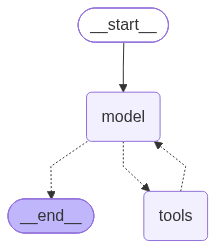

In [7]:
agent

In [8]:
user_input = "What is the current AI news for claude and then calculate 6 + 9"

for step in agent.stream(
    {"messages": user_input},
    stream_mode="values"
):

    step["messages"][-1].pretty_print()

================================ Human Message =================================

What is the current AI news for claude and then calculate 6 + 9
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_2264905)
 Call ID: call_2264905
  Args:
    query: Claude AI latest news
  calculator (call_2264906)
 Call ID: call_2264906
  Args:
    expression: 6 + 9
================================= Tool Message =================================
Name: calculator

15
================================== Ai Message ==================================

[{'type': 'text', 'text': '### Claude AI News\nAnthropic has recently been rolling out updates to its **Claude 5.5 model family** (including Claude Haiku 5.5 and Claude Sonnet 5.5) focusing on faster performance, lower operational costs, and higher efficiency for enterprise and high-volume work. Anthropic has also been making headlines regarding advancements in AI agents—notably reporting that 